# Probability

## Challenge 1
There is a box with 10 white balls, 12 red balls and 8 black balls. Calculate the probability of:
* Taking a white ball out.
* Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
* Taking a white ball on first extraction and a black ball out on second extraction replacing the first one.
* Taking 3 balls and them being all different colours.

In [4]:
white = 10
red = 12
black = 8
total = white + red + black

# 1. Probability of taking a white ball out
p_white = white / total

# 2. Probability of white first and black second (no replacement)
p_white_then_black_no_replace = (white / total) * (black / (total - 1))

# 3. Probability of white first and black second (with replacement)
p_white_then_black_replace = (white / total) * (black / total)

# 4. Probability of 3 balls being all different colors
p_diff_colors = (
    (white / total) * (red / (total - 1)) * (black / (total - 2)) +
    (white / total) * (black / (total - 1)) * (red / (total - 2)) +
    (red / total) * (white / (total - 1)) * (black / (total - 2)) +
    (red / total) * (black / (total - 1)) * (white / (total - 2)) +
    (black / total) * (white / (total - 1)) * (red / (total - 2)) +
    (black / total) * (red / (total - 1)) * (white / (total - 2))
)

p_white, p_white_then_black_no_replace, p_white_then_black_replace, p_diff_colors


(0.3333333333333333,
 0.09195402298850575,
 0.08888888888888888,
 0.23645320197044337)

## Challenge 2

You want to go on picnic on Saturday. You hate rain, and would know to plan your weekend. To help you make a decision, you gather the following data about rainy days:

* 40% of all days are cloudy.
* About 50% of cloudy days are rainy. 
* About 20% of non-cloudy days are rainy.

What is the chance of rain during next Saturday?

In [5]:
# P(Cloudy) = 0.4
# P(Rain | Cloudy) = 0.5
# P(Rain | Not Cloudy) = 0.2

p_cloudy = 0.4
p_rain_given_cloudy = 0.5
p_rain_given_not_cloudy = 0.2
p_rain = (p_cloudy * p_rain_given_cloudy) + ((1 - p_cloudy) * p_rain_given_not_cloudy)
p_rain


0.32

## Challenge 3

A and B are events of a probability such that $P(A) = 0.3$, $P(B) = 0.6$ and $P(A \cap B) = 0.1$

Which of the following statements are true?  
**HINT: draw a big Venn Diagram by your side**  
* $P(\overline{A}) = 0.7$
* $P(A \cup B) = 0.6$
* $P(A \cap \overline{B}) = 0.2$
* $P(A \cup \overline{A}) = 1$  
* $P(A \cap (B \cup \overline{B})) = 0.4$
* $P(\overline{A} \cap \overline{B}) = 0.3$
* $P(\overline{A \cap B}) = 0.9$

In [6]:
P_A = 0.3
P_B = 0.6
P_A_and_B = 0.1

results = {
    "P(not A) = 0.7": round(1 - P_A, 1) == 0.7,
    "P(A or B) = 0.6": round(P_A + P_B - P_A_and_B, 1) == 0.6,
    "P(A and not B) = 0.2": round(P_A - P_A_and_B, 1) == 0.2,
    "P(A or not A) = 1": True,  # always true
    "P(A and (B or not B)) = 0.3": round(P_A, 1) == 0.3,  # B or not B is universal set
    "P(not A and not B) = 0.3": round(1 - (P_A + P_B - P_A_and_B), 1) == 0.3,
    "P(not (A and B)) = 0.9": round(1 - P_A_and_B, 1) == 0.9
}

results


{'P(not A) = 0.7': True,
 'P(A or B) = 0.6': False,
 'P(A and not B) = 0.2': True,
 'P(A or not A) = 1': True,
 'P(A and (B or not B)) = 0.3': True,
 'P(not A and not B) = 0.3': False,
 'P(not (A and B)) = 0.9': True}

## Challenge 4

 * If someone flies to China, the probability of getting Covid is 1%  
 * If someone flies to Italy, the probability of getting Covid is 20%  

I roll 1 dice with numbers 1, 2, 3, 4, 5, 6:  
 * If 1: I fly to Italy
 * If not 1: I fly to China

During my trip, I got Covid. What is the probability that I flew to China?

In [7]:
# Prior probabilities
p_italy = 1/6
p_china = 5/6

# Likelihoods
p_covid_given_italy = 0.2
p_covid_given_china = 0.01

# Total probability of getting Covid
p_covid = p_italy * p_covid_given_italy + p_china * p_covid_given_china

# Bayes' Theorem: P(China | Covid)
p_china_given_covid = (p_china * p_covid_given_china) / p_covid
p_china_given_covid


0.2

## BONUS

You roll 2 dice. What is the probability that the sum of the numbers is 7? And 8? And 9? Then simulate 10000 times and draw a countplot.

your explanation here

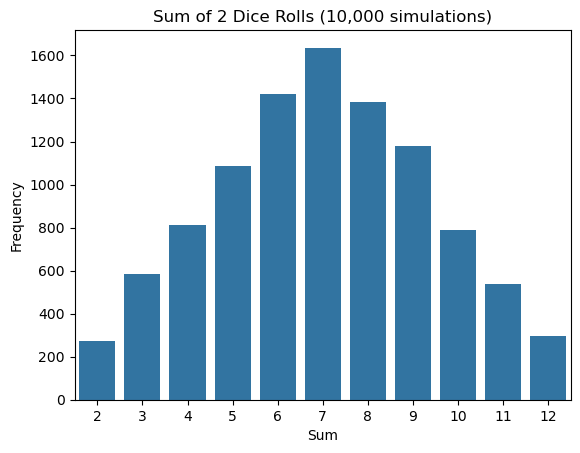

(0.16666666666666666, 0.1388888888888889, 0.1111111111111111)

In [8]:
import itertools
import random
import seaborn as sns
import matplotlib.pyplot as plt

# Theoretical probabilities
outcomes = list(itertools.product(range(1, 7), repeat=2))
sums = [sum(t) for t in outcomes]

p_7 = sums.count(7) / len(sums)
p_8 = sums.count(8) / len(sums)
p_9 = sums.count(9) / len(sums)

# Simulation
sim_sums = [random.randint(1, 6) + random.randint(1, 6) for _ in range(10000)]

# Plot
sns.countplot(x=sim_sums)
plt.title('Sum of 2 Dice Rolls (10,000 simulations)')
plt.xlabel('Sum')
plt.ylabel('Frequency')
plt.show()

p_7, p_8, p_9
